# Flying Blind and Recovering: An Invariant EKF for Quadrotor Attitude on SO(3)

*Why representing attitude as a rotation matrix $R \in SO(3)$ — instead of Euler
angles — is a modeling choice with consequences, demonstrated on a real
quadrotor figure-8 flight that survives a silent attitude-estimator fault.*

## Author

Andrea CIRILLO, drafted with an AI pair-programming assistant (Claude), based on a MATLAB
reference implementation and benchmark developed over the course of this project, and
built on top of `c4dynamics`'s own quadrotor cascade-PID (`quadcopter_pid.ipynb`) and
Euler-angle EKF (`quad_ekf.ipynb`) example notebooks.

## Goal

- Estimate the attitude $R \in SO(3)$ of a **real, flown** quadrotor (body
  $\to$ world rotation) from a gyroscope, an accelerometer, and a
  magnetometer, using an **Invariant Extended Kalman Filter** ($IEKF$)
  formulated directly on the Lie group $SO(3)$, with the gyro bias as an
  explicit additional state.
- Demonstrate the $IEKF$'s defining theoretical
  property — a propagation Jacobian that never depends on the *estimated*
  state — by subjecting it to the one scenario that property is built
  for: a silent, large attitude-estimator fault during a real flight, run
  side by side against `c4dynamics`'s existing Euler-angle $EKF$
  (`quad_ekf.ipynb`) on the *same* flight, the *same* fault, and the *same*
  sensor stream.


## Overview


**Why $R$ and not Euler angles?** 
Every attitude
filter needs some representation of orientation, and the three Euler
angles $(\varphi,\theta,\psi)$ look like the obvious, economical one: three
numbers, directly readable, no redundancy. This notebook's central claim
is that this convenience is deceptive, and that the full $3\times3$
rotation matrix $R$ — nine numbers for three degrees of freedom — is the
representation a serious attitude filter should use. Two concrete
consequences follow from that one choice, and both are demonstrated here,
not just asserted:



1. **Exact kinematics, no singularity.** $\dot R = R[\boldsymbol\omega]_\times$
   (section 3.3) is exact for *any* attitude, including the $\theta=\pm90°$
   gimbal-lock orientation where the Euler-angle kinematics divide by
   $\cos\theta=0$ and blow up.


2. **A propagation Jacobian that cannot itself be wrong.** Because
   gyro-driven attitude propagation on $SO(3)$ is *group-affine* (section 5.1),
   the error dynamics are governed by the *measured* angular rate alone —
   never by the *estimated* attitude. 
   A classical (multiplicative) $EKF$
   for attitude linearizes the error around the *current estimate*
   instead, 
   so if that estimate is badly wrong 
   — a cold start, a sensor
   dropout, a corrupted hand-off between subsystems — 
   the linearization
   itself is evaluated in the wrong place and the filter can fail to
   recover even when it keeps receiving good measurements afterward.


To demonstrate point 2, 
sections 7–8 fly a quadrotor a 
real figure-8 trajectory with a cascade-$PID$ controller, 
inject exactly this kind of
silent fault mid-flight into both an existing Euler-angle $EKF$ and this
notebook's $IEKF$, 
and show what each one does next 
— an existing
estimator's defining weakness and this one's defining strength, on the
same flight.

This notebook builds the theory from the ground up 
(section 2–5, with
terminology defined at first use for a reader comfortable with Kalman
filtering but new to Lie-group estimation), 
and demonstrates all of the above (sections 7–8) on
that real flight: 
nominal tracking, 
the attitude-fault recovery test,
gyro-bias estimation, 
and a filter-consistency check (NEES).

See Also: 
- 
- 
- 

## Table of Contents

1. [Setup](#1.-Setup)
2. [The Estimation Problem](#2.-The-Estimation-Problem)
3. [Dynamics](#3.-Dynamics)
4. [Sensors — The Measurements](#4.-Sensors-—-The-Measurements)
5. [Invariant Extended Kalman Filter](#5.-Invariant-Extended-Kalman-Filter)
6. [C4DYNAMICS — Implementation](#6.-C4DYNAMICS-—-Implementation)
7. [Simulation](#7.-Simulation)
8. [Results](#8.-Results)
9. [Summary & Conclusions](#9.-Summary-&-Conclusions)

## 1. Setup

The program is organized as follows: 

- A utility file [iekf.py](https://raw.githubusercontent.com/c4dynamics/c4dynamics/main/docs/source/programs/iekf_estimation/iekf.py) possesses the modules: 
  - the IEKF filer `iekf`. 
  - $SO(3)$ helpers `skewSym`, `expSO3` and `logSO3`.
- The quadrotor plant, its cascade-$PID$ controller, and the existing Euler-angle $EKF$ this notebook compares against are imported directly from c4dynamics
([quad_pid](https://github.com/c4dynamics/c4dynamics/blob/main/c4dynamics/controllers/quad_pid.py), [quad_ekf](https://github.com/c4dynamics/c4dynamics/blob/main/c4dynamics/utils/use_cases/quad_ekf.py), [c4dynamics.sensors.navigation](https://github.com/c4dynamics/c4dynamics/blob/main/c4dynamics/sensors/navigation.py))

### Download the utility file

`iekf.py` is not yet part of the `c4dynamics` package. 
The next cell downloads it from the c4dynamics GitHub repository into the notebook's folder, 
unless a local copy is already there.

In [ ]:
import os
import urllib.request

IEKF_URL = 'https://raw.githubusercontent.com/c4dynamics/c4dynamics/main/docs/source/programs/iekf_estimation/iekf.py'

if not os.path.exists('iekf.py'):
    urllib.request.urlretrieve(IEKF_URL, 'iekf.py')
    print('iekf.py downloaded')
else:
    print('iekf.py found locally')

In [1]:
import sys, os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

import c4dynamics as c4d
from c4dynamics.rotmat import dcm321, dcm321euler
from c4dynamics.controllers.quad_pid import run_fig8_pid
from c4dynamics.models.quad import default_quad_config
from c4dynamics.controllers.cascade_pid_config import default_controller_config
from c4dynamics.sensors.navigation import imu, magnetometer
from c4dynamics.utils.use_cases.quad_ekf import ekf_quad, STATE_NAMES
from c4dynamics.utils.use_cases.ekf_config import default_ekf_config

from iekf import iekf, skewSym, expSO3, logSO3

mpl.rcParams.update({
    'font.family': 'sans-serif', 'font.size': 12,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3,
})
print("c4dynamics + iekf imported")

c4dynamics + iekf imported


## 2. The Estimation Problem

The attitude of a rigid body is the rotation $R$ that maps a vector
expressed in the body frame to the same vector expressed in the world
frame: $\mathbf v_{world} = R \cdot \mathbf v_{body}$. $R$ is not observed
directly; it is reconstructed from:

- a rate **gyroscope**, whose integral *propagates* $R$ forward in time
  but drifts without bound on its own (section 4.1).
- an **accelerometer** and a **magnetometer**, each of which observes a
  known world-frame reference direction (gravity, the local magnetic
  field) rotated into the body frame, and *corrects* the propagated
  estimate (sections 4.2–4.3).

This is a sensor-fusion problem with one twist that gives this notebook
its subject: 
the quantity being estimated, $R$, does not live in a vector
space $\mathbb R^n$ the way a Kalman filter's state normally does — it
lives on the curved manifold $SO(3)$ (defined below), where ordinary
vector addition and subtraction are not even defined. 
Section 2.1 fixes the
vocabulary this forces; 
sections 3–5 build the filter around it.

### 2.1. Terminology at a Glance

A reader comfortable with ordinary (vector-state) Kalman filtering but
new to filtering on a Lie group needs the following terms, each also
introduced again, in context, where it is first used below:

| Term | Meaning here |
|---|---|
| $SO(3)$ | The *Special Orthogonal group* in 3 dimensions: the set of all $3\times3$ rotation matrices $R$ (orthogonal, $\det R=1$), with matrix multiplication as the group operation. The space this notebook's attitude estimate lives in (section 3.1, 3.3). |
| $\mathbb R^3$ | Ordinary 3-dimensional vector space — used both for physical angular rate $\boldsymbol\omega$ and, isomorphically, for the *Lie algebra* of $SO(3)$ (next row). |
| Lie algebra $\mathfrak{so}(3)$ | The space of $3\times3$ skew-symmetric matrices — the "tangent space" to $SO(3)$ at the identity. Isomorphic to $\mathbb R^3$ via $[\cdot]_\times$ (section 3.3); this is where the linear Kalman machinery actually operates (as the error state $\boldsymbol\delta$, next rows). |
| Group action | How a group acts on (transforms) something else — here, how $R\in SO(3)$ acts on a body-frame vector by $\mathbf v\mapsto R\mathbf v$, or on another rotation by $\hat R\mapsto \hat R\cdot\exp(\boldsymbol\delta)$ (next row). The $IEKF$ defines its error *through this action* rather than by subtraction. |
| Left-invariant error | The specific error definition used here: $R_{true}=\hat R\cdot\exp(\boldsymbol\delta)$, i.e. the correction is applied by *right-multiplying* the estimate — equivalently, expressed in the estimate's own body frame. ("Left-invariant" refers to a symmetry property of this definition under the group's left action; see section 5.) |
| Group-affine | The defining structural property of gyro-driven $SO(3)$ propagation (§5.1): the *error* dynamics $\dot{\boldsymbol\delta}$ depend affinely on $\boldsymbol\delta$ itself and on the *measured* input, but **not at all** on the nominal state $\hat R$. This is what makes the $IEKF$'s propagation Jacobian state-independent — the property §7–§8 demonstrate concretely. |
| ${SE}_2(3)$ | The *extended special Euclidean group*: $SO(3)\times\mathbb R^3\times\mathbb R^3$, pairing a rotation with two translational quantities (here, velocity and position, §3.1) into one group. Mentioned in §3.1 for context on the full rigid-body state the quadrotor plant evolves on; this notebook's $IEKF$ itself estimates only the $SO(3)$ (plus bias) part of it. |
| Multiplicative EKF | The classical alternative to the $IEKF$ for attitude: it also keeps $R$ off the plain linear state vector and injects corrections multiplicatively, but defines the error by linearizing around the *current estimate* $\hat R$ rather than through group-affine propagation — so, unlike the $IEKF$, its propagation Jacobian *does* depend on $\hat R$ (§5.1, §8.2). `c4dynamics`'s existing quadrotor $EKF$ (§3.3, §7.5, §8.2) is not quite this (it is Euler-angle-based, not multiplicative-$SO(3)$-based), but shares the same root vulnerability: its propagation Jacobian is evaluated at the current state estimate. |
| Error state vs. nominal/full state | The $IEKF$ keeps two distinct things (§6): the **nominal state** $(\hat R,\hat{\mathbf b})$ — the actual attitude and bias estimate, living on $SO(3)\times\mathbb R^3$ — and the **error state** $\mathbf x=[\boldsymbol\delta;\boldsymbol\beta]\in\mathbb R^6$ — the *linear*, always-zero-mean quantity the Kalman recursion actually propagates and corrects, which is injected into the nominal state and reset to zero after every update (§6). |



## 3. Dynamics

This section describes the physical plant model of the quadrotor whose
attitude this notebook estimates 
— the actual `c4dynamics` rigid-body
model and cascade-$PID$ controller behind `quadcopter_pid.ipynb` and
`quad_ekf.ipynb` (section 7 flies it directly, via `c4dynamics.controllers.quad_pid`,
rather than re-deriving it here).

### 3.1. State Vector

The vehicle is modeled as a rigid body evolving on
${SE}_2(3) = SO(3)\times\mathbb R^3\times\mathbb R^3$ (the *extended pose*,
section 2.1), rather than as a $12$-entry vector of Euler angles and Cartesian
coordinates. The plant state is

$$\mathbf x = (R,\ \boldsymbol\omega,\ \mathbf v,\ \mathbf p)$$

- $R \in {SO}(3)$: attitude, body $\to$ world rotation — the quantity this
  notebook's $IEKF$ estimates (section 5)
- $\boldsymbol\omega \in \mathbb R^3$: body-frame angular rate $[rad/s]$
- $\mathbf v \in \mathbb R^3$: world-frame velocity $[m/s]$
- $\mathbf p \in \mathbb R^3$: world-frame position $[m]$

Representing attitude by $R$ rather than by Euler angles
$(\varphi,\theta,\psi)$ is a deliberate, consequential choice, not a
notational preference: it is what makes the exact, gimbal-lock-free
kinematics below possible, and what the $IEKF$'s group-affine error
dynamics (§5.1) rely on. `c4dynamics`'s own quadrotor plant
(`c4dynamics.controllers.quad_pid.dynamics`, flown directly in §7)
internally represents attitude with the Euler triple
$(\varphi,\theta,\psi)$ for its own, independent reasons (it is the
representation its existing cascade-$PID$ controller and Euler-angle
$EKF$ are built around) — this notebook's $IEKF$ never touches that
representation directly; it reconstructs $R$ from the *same gyro,
accelerometer and magnetometer measurements* the real vehicle produces
(§7.3), exactly as a real onboard attitude filter would.

### 3.2. Coordinate Frames

- **Body frame $B$**: origin at the center of mass; $x$ forward, $y$
  right, $z$ down — the $FRD$ (front-right-down) convention, matching
  `c4dynamics.controllers.quad_pid` — see §3.4 for the layout of the four
  rotors relative to these axes.
- **Position/velocity** ($\mathbf p,\mathbf v$ in §3.1) are tracked by the
  real quadrotor plant in an $ENU$ (East-North-Up) world frame — this is
  `c4dynamics.controllers.quad_pid`'s own convention for the
  *translational* dynamics, and §7's flight inherits it unchanged; it
  plays no further role in this notebook, since the $IEKF$ does not
  estimate position or velocity.
- **Attitude** ($R$ in §3.1, and the Euler triple $(\varphi,\theta,\psi)$
  the real plant uses internally) is governed, independently of that
  position convention, by the standard aerospace $3$-$2$-$1$ kinematics
  (§3.3) and by `c4dynamics`'s `dcm321(\varphi,\theta,\psi)` — which is
  the rotation from a **North-East-Down ($NED$)-style attitude/navigation
  frame to the body frame**, the convention `c4dynamics`'s own
  accelerometer and magnetometer *sensor* models (`c4dynamics.sensors.navigation`,
  §4, §7.3) are built against, verified directly against that code in §7.3's
  worked calibration. Concretely: $\mathbf g = [0,0,g]^\top$, $g>0$ (gravity
  points along $+z$, i.e. down), and $R$ in this notebook is related to
  `c4dynamics`'s own $\varphi,\theta,\psi$ by
  $R = \mathrm{dcm321}(\varphi,\theta,\psi)^\top$ (body $\to$ this $NED$-style
  frame). Mixing the translational ($ENU$) and attitude ($NED$-style)
  conventions of one real codebase like this is exactly the kind of
  cross-convention bookkeeping flagged as a common source of sign errors
  in §3.5 — spelled out explicitly here rather than silently assumed.
- $R$ maps body-frame vectors to the attitude/navigation frame:
  $\mathbf v_{nav} = R\,\mathbf v_{B}$.

### 3.3. Equations of Motion

**Attitude kinematics.** Given the body-frame angular velocity
$\boldsymbol\omega(t)\in\mathbb R^3$ measured by the gyroscope, $R$
evolves as

$$\dot R = R\,[\boldsymbol\omega]_\times,$$

where $[\boldsymbol\omega]_\times$ is the *skew-symmetric matrix*
associated with $\boldsymbol\omega$ (§2.1), defined so that
$[\boldsymbol\omega]_\times \mathbf v = \boldsymbol\omega \times \mathbf
v$ for any $\mathbf v \in \mathbb R^3$ — the isomorphism between
$\mathbb R^3$ and $\mathfrak{so}(3)$, the Lie algebra of $SO(3)$ (§2.1).
This is exact for every attitude, including $\theta=\pm90°$, where the
real plant's *own* Euler-angle kinematics,

$$\dot\varphi = p + (q\sin\varphi+r\cos\varphi)\tan\theta,\qquad
\dot\theta = q\cos\varphi - r\sin\varphi,\qquad
\dot\psi = \frac{q\sin\varphi+r\cos\varphi}{\cos\theta},$$

divide by $\cos\theta=0$ — the concrete form of the "exact kinematics, no
singularity" claim made in the Overview.

**The exponential map.** A constant angular velocity applied for a
duration equal to the norm of a rotation vector
$\boldsymbol\phi \in \mathbb R^3$ (direction = rotation axis, norm =
angle in radians) produces the rotation

$$\exp(\boldsymbol\phi) = I + \sin(\theta)K + (1-\cos\theta)K^2,
\qquad K = [\boldsymbol\phi/\theta]_\times,\ \ \theta = \|\boldsymbol\phi\|$$

(Rodrigues' formula). This replaces vector addition when moving a rotation
by a small increment: instead of $R+\delta$ (not defined, since $SO(3)$ is
not a vector space, §2.1), we use $R\cdot\exp(\boldsymbol\phi)$, always a
valid rotation — a concrete instance of the *group action* (§2.1). Its
inverse, $\log: SO(3)\to\mathfrak{so}(3)$, recovers $\boldsymbol\phi$ from
a rotation matrix; $\|\log(R)\|$ is the **geodesic distance** on $SO(3)$ —
the metric used throughout this notebook to report attitude error.

**Discrete propagation.** Over a short sample interval $\Delta t$, with
$\boldsymbol\omega$ measured (held constant over the interval),

$$R_{k+1} = R_k \cdot \exp(\boldsymbol\omega_k\,\Delta t)$$

— exact on the group (no small-angle approximation, no re-normalization
needed). The code cell below implements `skewSym`, `expSO3`, `logSO3` and
checks the round-trip $\exp(\log(R))=R$.

In [2]:
# skewSym, expSO3 and logSO3 are imported from iekf.py (Section 1).

# sanity check: exp(log(R)) == R for a generic rotation
R_test = expSO3(np.array([0.3, -0.5, 0.2]))
roundtrip_err = np.linalg.norm(expSO3(logSO3(R_test)) - R_test)
print(f"round-trip error: {roundtrip_err:.2e}  (should be ~1e-16)")

round-trip error: 1.52e-16  (should be ~1e-16)


### 3.4. Illustrations

The figure below shows the $X$-configuration rotor layout in the body
frame defined in §3.2 (top-down view, $z_B$ into the page), matching
`c4dynamics.controllers.quad_pid`'s motor-mixing convention (§7.1).

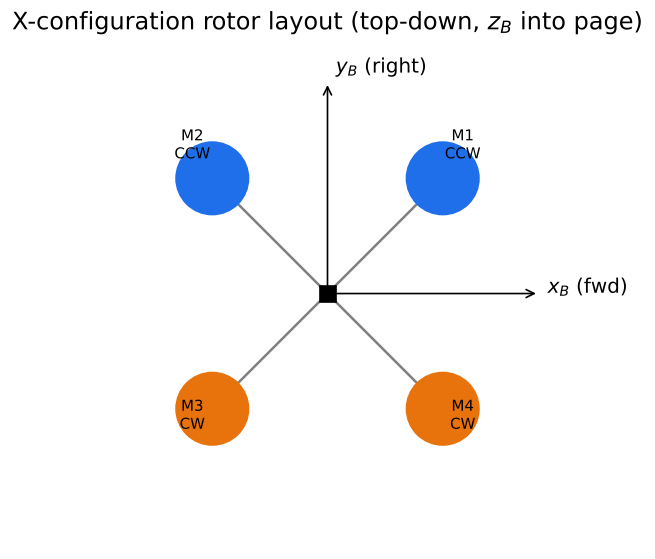

In [3]:
l = 0.225
az_deg = [45, 135, 225, 315]
spin = ['CCW', 'CCW', 'CW', 'CW']
labels = ['M1', 'M2', 'M3', 'M4']
colors = ['#1f6feb', '#1f6feb', '#e8720c', '#e8720c']

fig, ax = plt.subplots(figsize=(5, 5), dpi=120)
ax.plot(0, 0, 'ks', ms=10)
for az, s, lab, c in zip(az_deg, spin, labels, colors):
    th = np.deg2rad(az)
    x, y = l*np.cos(th), l*np.sin(th)
    ax.plot([0, x], [0, y], color='0.5', lw=1.5, zorder=1)
    ax.add_patch(plt.Circle((x, y), 0.05, color=c, zorder=2))
    ax.annotate(f"{lab}\n{s}", (x, y), textcoords="offset points",
                xytext=(12*np.sign(x) if x != 0 else 12, 12*np.sign(y) if y != 0 else 12),
                ha='center', fontsize=9)
ax.annotate('', xy=(l*1.3, 0), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='k'))
ax.annotate('$x_B$ (fwd)', (l*1.3, 0), textcoords="offset points", xytext=(5, 0))
ax.annotate('', xy=(0, l*1.3), xytext=(0, 0), arrowprops=dict(arrowstyle='->', color='k'))
ax.annotate('$y_B$ (right)', (0, l*1.3), textcoords="offset points", xytext=(5, 5))
ax.set_xlim(-0.35, 0.35); ax.set_ylim(-0.35, 0.35)
ax.set_aspect('equal'); ax.set_title('X-configuration rotor layout (top-down, $z_B$ into page)')
ax.axis('off')
plt.tight_layout(); plt.show()

### 3.5. Challenges, Highlights, and Interesting Issues

- **The specific-force degeneracy.** For a thrust-only rigid body, the
  accelerometer's body-frame reading is dominated by
  $-T/m$ along the body $z$-axis whenever the vehicle is near hover
  ($T\approx mg$), but during a real horizontal maneuver (§7's figure-8)
  the vehicle also accelerates translationally, and the accelerometer
  measures that *combined* specific force, not gravity alone — treating
  its reading as a pure gravity-direction reference is only valid near
  hover. §7.5 addresses this with the $IEKF$'s own built-in adaptive
  measurement-noise inflation (down-weighting the accelerometer update
  whenever its magnitude departs from $1g$, exactly the regime where the
  degeneracy bites) rather than by avoiding maneuvering flight.
- **Exact vs. first-order rotation integration.** Propagating $R$ via
  $R_k\exp(\boldsymbol\omega_k\Delta t)$ (§3.3) rather than
  $R_k + \dot R_k\Delta t$ keeps $R$ exactly orthonormal at every step —
  a first-order Euler step does not, and accumulates drift that
  eventually requires re-orthonormalization (e.g. via $SVD$), a
  workaround needed by fixed-gain baselines (Mahony, Madgwick, in this
  project's companion MATLAB benchmark) but never needed here.
- **Frame convention discipline.** $NED$-style attitude kinematics
  alongside an $ENU$ position/velocity convention, in one and the same
  real codebase, is not a hypothetical — it is exactly what
  `c4dynamics.controllers.quad_pid` does (§3.2), and getting the two
  crossed is the single most common source of sign errors in a project
  like this one.
- **A silent estimator fault is the real test, not a cold start.** A
  cold start is forgiving in one respect: the filter *knows* it is
  starting from nothing, and its own reported covariance reflects that.
  What §7.4–§8.2 inject is harder: a large attitude error with the
  filter's covariance left exactly as it was, unaware anything happened —
  the handoff/corruption scenario a classical linearize-around-the-estimate
  filter is least equipped for, because its own confidence in a now-wrong
  estimate actively works against recovering from it.

## 4. Sensors — The Measurements

### 4.1. Gyroscope

$$\boldsymbol\omega_{meas}(t) = \boldsymbol\omega_{true}(t) + \mathbf b + \mathbf n_g(t)$$

where $\boldsymbol\omega_{true}$ is the true body-frame angular velocity
$[rad/s]$, $\mathbf b$ is a gyro bias $[rad/s]$, and
$\mathbf n_g \sim \mathcal N(0, \sigma_{gyro}^2 I)$ is white measurement
noise. The $IEKF$'s own process model (§5.1) treats $\mathbf b$ as a
**random walk**, $\dot{\mathbf b} = \mathbf n_b$ — the standard, honest
assumption for a real gyro, whose bias genuinely drifts slowly over a
flight. §7's simulated sensor (`c4dynamics.sensors.navigation.imu`), like
most compact simulated-IMU models (and this project's own earlier
MATLAB benchmark), injects a **constant** bias for the duration of one
flight: a zero-rate special case of that same random walk, not a
different model — a real bias does not reset at every timestep, so
"constant over one ~30 s flight" and "a slowly-varying random walk" are
the same statement at this timescale, and the filter's nonzero
$\sigma_{bias}$ (§5.1, §7.5) is exactly what lets it still *track* a
non-constant bias, should one occur over a longer flight.

### 4.2. Accelerometer

With no linear acceleration (or when it is small relative to gravity),
the accelerometer measures the **specific force** direction — the
reaction to gravity, which for a body at rest points *opposite* gravity —
as seen in the body frame:

$$\mathbf a_{meas} = R^\top \mathbf g_{ref} + \mathbf n_a, \qquad
\mathbf n_a \sim \mathcal N(0, \sigma_{acc}^2 I)$$

where $\mathbf g_{ref}=[0,0,-1]$ is this *specific-force* reference
direction in the attitude/navigation frame of §3.2 — the negative of the
gravity-direction unit vector $[0,0,1]$ (gravity points down, $+z$, in
that $NED$-style frame; a stationary accelerometer reads the opposite,
"up", reaction). This single vector observation constrains $2$ of the
$3$ attitude degrees of freedom (it cannot see rotation about its own
axis) — the classical "roll/pitch from accelerometer, yaw needs
something else" statement. See §3.5 for why, in real (maneuvering)
flight, this is only an approximation, and how §7.5 compensates.

### 4.3. Magnetometer

$$\mathbf m_{meas} = R^\top \mathbf m_{ref} + \mathbf n_m, \qquad
\mathbf n_m \sim \mathcal N(0, \sigma_{mag}^2 I)$$

with $\mathbf m_{ref}$ the local magnetic field direction in the
attitude/navigation frame, taken directly from
`c4dynamics.sensors.navigation.magnetometer`'s own reference-field
construction (§7.3) rather than hand-derived, so the sign convention is
guaranteed to match what the simulated sensor actually produces:
$\mathbf m_{ref} = [\cos I\cos D,\ \cos I\sin D,\ \sin I]$ with
inclination $I>0$ (a **positive**, i.e. *downward*-dipping, $z$ component
in this $NED$-style frame) and declination $D$ — the standard Northern-hemisphere
convention (at the Southern hemisphere, the field points up instead, i.e.
$I<0$). Combined with the accelerometer (two non-parallel reference
vectors), the full $3$-DOF attitude becomes observable.

### 4.4. Summary

| Sensor | Measures | World-frame reference | Constrains |
|---|---|---|---|
| Gyroscope | $\boldsymbol\omega + \mathbf b$ | — | propagation only |
| Accelerometer | $R^\top \mathbf g_{ref}$ | specific-force direction | roll, pitch |
| Magnetometer | $R^\top \mathbf m_{ref}$ | magnetic field direction | yaw |

§7.3 exercises the real `c4dynamics` sensor classes directly (not a
reimplementation), and includes a short worked calibration confirming the
$\mathbf g_{ref}$/$\mathbf m_{ref}$ conventions above against them
numerically, rather than asserting them.

## 5. Invariant Extended Kalman Filter

The estimation error is defined through the group action instead of
subtraction (§2.1), as a body-frame ("left-invariant", §2.1) error:

$$R_{true} = \hat R \cdot \exp(\boldsymbol\delta) \qquad\Longleftrightarrow\qquad
\boldsymbol\delta = \log\!\left(\hat R^\top R_{true}\right)$$

where $\hat R$ is the current estimate and $\boldsymbol\delta \in
\mathbb R^3$ is the error expressed in the Lie algebra $\mathfrak{so}(3)
\cong \mathbb R^3$ (§2.1) — which *is* a vector space, so the standard
Gaussian/Kalman machinery (means, covariances, linear updates) applies
to $\boldsymbol\delta$ consistently.

The error state augments $\boldsymbol\delta$ with the gyro-bias error
$\boldsymbol\beta = \mathbf b_{true} - \hat{\mathbf b}$:

$$\mathbf x = \begin{bmatrix}\boldsymbol\delta \\ \boldsymbol\beta\end{bmatrix} \in \mathbb R^6$$

— the **error state** of §2.1's glossary, kept distinct from the
**nominal state** $(\hat R,\hat{\mathbf b})$.

### 5.1. Process Model — The Predict Stage

Differentiating the error definition above along the true and estimated
dynamics gives the **linearized** error dynamics

$$\dot{\boldsymbol\delta} = -[\hat{\boldsymbol\omega}]_\times \boldsymbol\delta -
\boldsymbol\beta - \mathbf n_g, \qquad \dot{\boldsymbol\beta} = \mathbf n_b$$

where $\hat{\boldsymbol\omega} = \boldsymbol\omega_{meas} -
\hat{\mathbf b}$ is the bias-corrected measured rate. **This is the
group-affine property (§2.1)**: the transition depends only on
$\hat{\boldsymbol\omega}$ — a *measured* quantity — never on $\hat R$
itself. The discrete transition Jacobian is therefore

$$F_k = \begin{bmatrix} \exp(-\hat{\boldsymbol\omega}_k \Delta t) & -I\,\Delta t \\ 0 & I \end{bmatrix}, \qquad
P_{k+1}^- = F_k P_k F_k^\top + Q_k$$

with $Q_k = \mathrm{blkdiag}(\sigma_{gyro}^2 I,\ \sigma_{bias}^2 I)\,\Delta t$.
The nominal state itself is propagated *exactly* on the group (§3):

$$\hat R_{k+1}^- = \hat R_k \cdot \exp(\hat{\boldsymbol\omega}_k \Delta t), \qquad
\hat{\mathbf b}_{k+1}^- = \hat{\mathbf b}_k$$

Contrast this with a **multiplicative EKF** (§2.1) or, as used in
`c4dynamics`'s existing quadrotor estimator (§3.3, §7.5), an Euler-angle
$EKF$: both linearize their propagation Jacobian *at the current state
estimate*. When that estimate is correct, the difference is invisible;
§8.2 shows what happens to each filter's Jacobian — and therefore its
recovery — when it is not.

### 5.2. Measurement Model — The Update Stage

For a known world-frame reference vector $\mathbf v_{ref}$ (gravity or
magnetic field, §4) observed in the body frame,

$$\mathbf y = R^\top \mathbf v_{ref} + \text{noise}, \qquad
\hat{\mathbf y} = \hat R^\top \mathbf v_{ref}$$

Linearizing $\mathbf y - \hat{\mathbf y}$ in $\boldsymbol\delta$ gives

$$\mathbf y - \hat{\mathbf y} \approx [\hat{\mathbf y}]_\times \boldsymbol\delta + \text{noise}
\qquad\Longrightarrow\qquad H = \begin{bmatrix}[\hat{\mathbf y}]_\times & 0\end{bmatrix}$$

and the standard Kalman correction follows:

$$K = P H^\top (H P H^\top + R_{meas})^{-1}, \qquad
\begin{bmatrix}\hat{\boldsymbol\delta}\\\hat{\boldsymbol\beta}\end{bmatrix} = K(\mathbf y - \hat{\mathbf y})$$

**Injection.** Unlike a linear Kalman filter, the correction is not
added to the state — it is *injected* through the exponential map, which
is what keeps $\hat R$ a valid rotation at every step:

$$\hat R \leftarrow \hat R \cdot \exp(\hat{\boldsymbol\delta}), \qquad
\hat{\mathbf b} \leftarrow \hat{\mathbf b} + \hat{\boldsymbol\beta}$$

followed by the usual covariance update (Joseph form, for numerical
robustness) and, critically, a **reset of the error state to zero** —
see §6 for why this matters when built on top of a generic linear-Kalman
base class.

The accelerometer and magnetometer are each applied as a **separate,
sequential** vector update at every step (accelerometer, then
magnetometer): each individually constrains only part of the attitude
(§4), and processing them one at a time keeps every update a plain
$3$-dimensional linear correction. §7.5 additionally applies **adaptive**
inflation of the accelerometer's $R_{meas}$ (§3.5, §4.2) whenever the raw
measurement departs from $1g$, down-weighting it exactly when the
specific-force degeneracy is most active.

## 6. C4DYNAMICS — Implementation

`c4dynamics.filters.kalman` provides the linear predict/update machinery
(`self.X`, `self.F`, `self.H`, `self.P`, `self.Q`, `self.R`);
`c4dynamics.filters.ekf` extends it for a nonlinear *vector* state via a
derivative `fx`. Neither fits a group-valued state directly — $\hat R$
cannot be added to a plain array the way `ekf.predict(fx=...)` adds a
vector derivative.

**The pattern used here (an error-state Kalman filter):** the *nominal*
state — the rotation `self.Rot` and the bias `self.b` — is kept as a
plain attribute on the object, separate from `self.X`. `self.X` is what
`kalman` actually manages: the Lie-algebra error state
$[\boldsymbol\delta;\boldsymbol\beta]$, always zero-mean. `predict()`
advances `self.Rot` on the group directly and lets the parent grow only
`self.P`; `update()` lets the parent compute the Kalman gain and update
`self.X`, then *injects* the result into `self.Rot`/`self.b` via
`expSO3` and resets `self.X` back to zero. This mirrors how `ekf`
accommodates a nonlinear vector field, except the nonlinearity here is
the group structure of $SO(3)$ rather than a nonlinear vector function.

Two points confirmed against the real `kalman.py` source during
development, worth carrying into a review of the class:

1. **Naming**: `kalman` already uses `self.R` for the measurement noise
   covariance (its `R` constructor argument) — the rotation is kept on
   `self.Rot` to avoid silently clobbering it.
2. **Scalar `P0`**: the parent does *not* auto-expand a bare scalar to
   `scalar * eye(n)` for `n > 1` (`np.atleast_2d(scalar)` gives a
   `(1, 1)` matrix regardless of `n`) — the class expands it itself
   before construction.

The class is in `iekf.py`, imported in §1. Its interface:

- `iekf(R0, b0, P0, sigmaGyro, sigmaBias)`: initial attitude and bias
  estimates, initial error covariance, and gyro / bias-walk noise.
- `predict(gyro, dt)`: propagate with one gyro sample (§5.1).
- `update(y, ref, Rmeas, adaptive=False)`: correct with one body-frame
  observation `y` of the known world-frame direction `ref` (§5.2).
  Called once for the accelerometer and once for the magnetometer at
  every step.
- `Rot`, `b`, `P`: the attitude estimate, the bias estimate, and the
  error-state covariance.

## 7. Simulation

Unlike this notebook's earlier synthetic-trajectory draft, every quantity
below is produced by **actually flying** the real `c4dynamics` quadrotor
plant on a real figure-8, under its own cascade-$PID$ controller and its
own rigid-body dynamics — not a prescribed, idealized $R(t)$. This section
builds, in order: the true flight (7.1), its main estimation loop as a
flowchart (7.2), the onboard sensor stream derived from that flight
(7.3), the attitude-fault event (7.4), and the two estimators run side by
side over all of it (7.5).

### 7.1. The True Quadrotor Flight

The vehicle, controller, and figure-8 reference are exactly
`quadcopter_pid.ipynb`'s own (`default_quad_config`,
`default_controller_config`, the same $A,B,\omega,z_{ref}$): an
$8\,s$ takeoff, a cruise phase flying the figure-8 under perfect-state
feedback (truth-fed control — the attitude-estimation question this
notebook asks is deliberately kept separate from whether an estimate is
good enough to *fly on*, which is `quad_ekf.ipynb`'s own question), and
an $8\,s$ landing. The true attitude $R_{true}(t)$ used for every error
metric below is computed from the flight's own Euler history via
$R=\mathrm{dcm321}(\varphi,\theta,\psi)^\top$ (§3.2) — not generated
separately, so it is exact by construction.

In [4]:
quadcopter = default_quad_config()
controller = default_controller_config()
trajectory = {'A': 4.0, 'B': 2.0, 'omega': 0.1, 'z_ref': 5.0}
simulation = {'dt': 5e-3, 'tf': 30.0}
config = {'quad': quadcopter, 'controller': controller,
          'trajectory': trajectory, 'sim': simulation}

quad = run_fig8_pid(config)

t = quad.data('x')[0]
N = len(t)

def col(name):
    return np.asarray(quad.data(name)[1])

Xtrue = np.vstack([col(n) for n in STATE_NAMES]).T      # N x 12
w1, w2, w3, w4 = col('w1'), col('w2'), col('w3'), col('w4')

Rtrue = np.zeros((3, 3, N))
for k in range(N):
    Rtrue[:, :, k] = dcm321(Xtrue[k, 6], Xtrue[k, 7], Xtrue[k, 8]).T

print(f"Flight: {t[-1]:.1f} s, {N} samples at {1/simulation['dt']:.0f} Hz")

Simulation start  |  tf = 30.0 s  |  dt = 0.005 s


Simulation complete.
Flight: 30.0 s, 6000 samples at 200 Hz


### 7.2. Main-Loop Flowchart

Every subsequent subsection is one pass through the loop below, run once
per $200\,Hz$ sample over the whole flight.

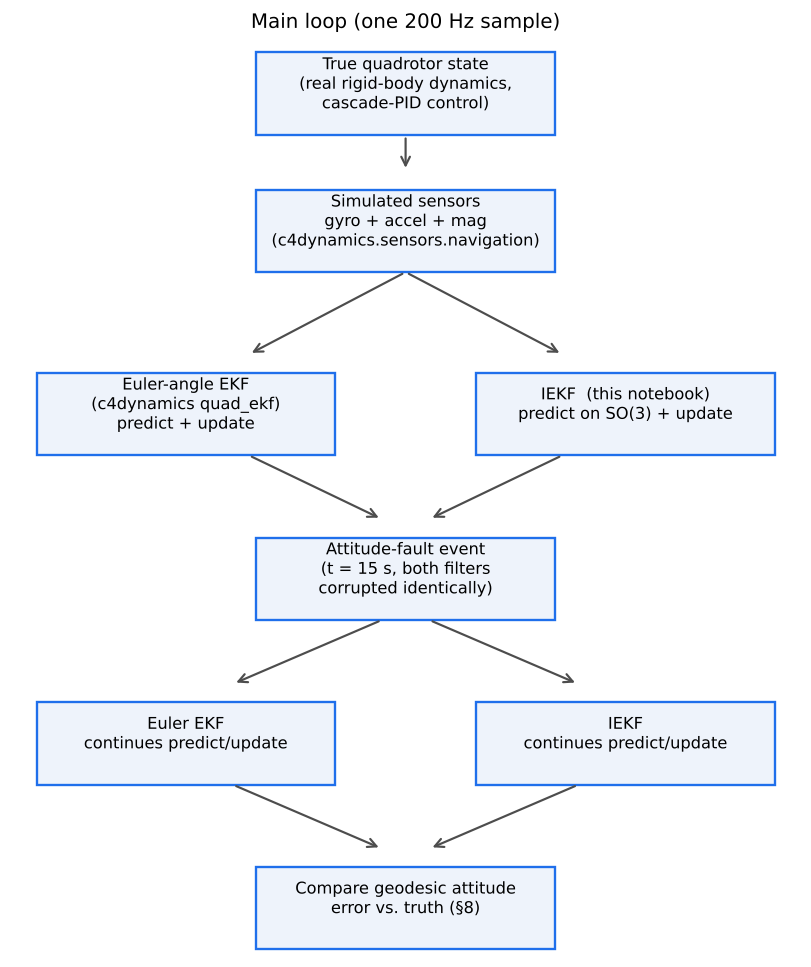

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 7.6), dpi=130)
ax.axis('off')

boxes = [
    (0.5, 0.95, "True quadrotor state\n(real rigid-body dynamics,\ncascade-PID control)"),
    (0.5, 0.80, "Simulated sensors\ngyro + accel + mag\n(c4dynamics.sensors.navigation)"),
    (0.22, 0.60, "Euler-angle EKF\n(c4dynamics quad_ekf)\npredict + update"),
    (0.78, 0.60, "IEKF  (this notebook)\npredict on SO(3) + update"),
    (0.5, 0.42, "Attitude-fault event\n(t = 15 s, both filters\ncorrupted identically)"),
    (0.22, 0.24, "Euler EKF\ncontinues predict/update"),
    (0.78, 0.24, "IEKF\ncontinues predict/update"),
    (0.5, 0.06, "Compare geodesic attitude\nerror vs. truth (§8)"),
]
for x, y, txt in boxes:
    ax.add_patch(plt.Rectangle((x-0.19, y-0.055), 0.38, 0.09, fc='#eef3fb',
                                ec='#1f6feb', lw=1.3, zorder=2))
    ax.text(x, y, txt, ha='center', va='center', fontsize=9, zorder=3)

arrows = [(0.5,0.895,0.5,0.855),
          (0.5,0.745,0.30,0.655),(0.5,0.745,0.70,0.655),
          (0.30,0.545,0.47,0.475),(0.70,0.545,0.53,0.475),
          (0.47,0.365,0.28,0.295),(0.53,0.365,0.72,0.295),
          (0.28,0.185,0.47,0.115),(0.72,0.185,0.53,0.115)]
for x0,y0,x1,y1 in arrows:
    ax.annotate('', xy=(x1,y1), xytext=(x0,y0),
                arrowprops=dict(arrowstyle='->', color='0.3', lw=1.2))

ax.set_xlim(0,1); ax.set_ylim(0,1)
ax.set_title('Main loop (one 200 Hz sample)', fontsize=11)
plt.tight_layout(); plt.show()

### 7.3. Onboard Sensors

Gyro and accelerometer are sampled at the simulation rate ($200\,Hz$);
the magnetometer is decimated to $50\,Hz$ (`ekf_cfg['mag_rate']`),
matching `quad_ekf.ipynb`'s own sensor configuration
(`default_ekf_config`). Both $\mathbf g_{ref}$ and $\mathbf m_{ref}$ (§4)
are calibrated here directly against the real sensor classes (not
hand-derived), by measuring their output at a known, zero attitude —
where body and attitude/navigation frames coincide, so the reference
vector *is* the measured direction — and then checking that prediction
holds at several further, non-trivial attitudes.

In [6]:
ekf_cfg = default_ekf_config()
imu_sensor = imu(gyro_std=ekf_cfg['gyro_std'], acc_std=ekf_cfg['acc_std'])
mag_sensor = magnetometer(noise_std=ekf_cfg['mag_std'],
                           inclination=ekf_cfg['mag_inclination'],
                           declination=ekf_cfg['mag_declination'])

# --- calibrate gRef, mRef against the real sensor models (§3.2, §4) ---
def _test_attitude(phi, theta, psi):
    rb = c4d.rigidbody(phi=phi, theta=theta, psi=psi)
    imu_ideal = imu(isideal=True)
    imu_ideal.measure(rb, t=0.0)
    ax_, ay_, az_, *_ = imu_ideal.measure(rb, t=0.01)   # zero v-dot -> pure gravity term
    accdir = np.array([ax_, ay_, az_]); accdir /= np.linalg.norm(accdir)
    mag_ideal = magnetometer(isideal=True, inclination=ekf_cfg['mag_inclination'])
    mdir = np.array(mag_ideal.measure(np.array([0,0,0,0,0,0,phi,theta,psi,0,0,0])))
    mdir /= np.linalg.norm(mdir)
    return dcm321(phi, theta, psi).T, accdir, mdir

R0_, acc0_, mag0_ = _test_attitude(0.0, 0.0, 0.0)
gRef = acc0_.copy()                                    # = [0, 0, -1], as derived in §4.2
mRef = mag_sensor.mref / np.linalg.norm(mag_sensor.mref)

max_err = 0.0
for phi, theta, psi in [(np.deg2rad(30),0,0), (0,np.deg2rad(25),0),
                         (0,0,np.deg2rad(40)), (np.deg2rad(20),np.deg2rad(-15),np.deg2rad(50))]:
    R_, acc_, mag_ = _test_attitude(phi, theta, psi)
    max_err = max(max_err, np.linalg.norm(R_.T @ gRef - acc_), np.linalg.norm(R_.T @ mRef - mag_))

print("gRef =", np.round(gRef, 4), "   mRef =", np.round(mRef, 4))
print(f"max |predicted - measured| direction error across test attitudes: {max_err:.1e}  (should be ~0)")

# --- generate the sensor stream from the true flight (§7.1) ---
proxy = c4d.rigidbody()
gyro_hist = np.zeros((3, N)); acc_hist = np.zeros((3, N)); mag_hist = np.zeros((3, N))
mag_decim = ekf_cfg['mag_rate']

np.random.seed(7)
for k in range(N):
    proxy.X = Xtrue[k].copy()
    axm, aym, azm, pm, qm, rm = imu_sensor.measure(proxy, t=t[k])
    gyro_hist[:, k] = [pm, qm, rm]
    acc_hist[:, k] = [axm, aym, azm]
    if k % mag_decim == 0:
        mag_hist[:, k] = mag_sensor.measure(Xtrue[k])

print(f"Sensor stream generated: gyro/accel @ {1/simulation['dt']:.0f} Hz, mag @ "
      f"{1/simulation['dt']/mag_decim:.0f} Hz")

gRef = [ 0.  0. -1.]    mRef = [0.5   0.    0.866]
max |predicted - measured| direction error across test attitudes: 1.4e-16  (should be ~0)
Sensor stream generated: gyro/accel @ 200 Hz, mag @ 50 Hz


### 7.4. The Attitude-Fault Event

At $t=15\,s$ (mid-cruise), **both** filters' attitude estimates are
forcibly overwritten with the *same* $90°$ rotation error relative to
truth — simulating a corrupted handoff, a bad reinitialization, or a
transient estimator fault — with **no corresponding inflation of either
filter's reported covariance**: a silent fault, not a self-aware reset
(§3.5). Everything else (the true flight, the sensor stream, both
filters' internal bias/covariance bookkeeping otherwise) continues
unmodified.

In [7]:
t_fault = 15.0
k_fault = int(np.argmin(np.abs(t - t_fault)))
fault_axis = np.array([0.0, 1.0, 0.0])
fault_angle = np.deg2rad(90.0)

def inject_fault(R_true_now):
    return R_true_now @ expSO3(fault_angle * fault_axis)

print(f"Attitude fault scheduled at t={t[k_fault]:.3f} s (index {k_fault}): "
      f"a {np.rad2deg(fault_angle):.0f} deg rotation about {fault_axis}, injected identically "
      f"into both filters' estimates, with no covariance change.")

Attitude fault scheduled at t=15.000 s (index 3000): a 90 deg rotation about [0. 1. 0.], injected identically into both filters' estimates, with no covariance change.


### 7.5. Running Both Estimators

The Euler-angle $EKF$ is `c4dynamics.utils.use_cases.quad_ekf.ekf_quad` —
the *actual* class behind `quad_ekf.ipynb`, run here open-loop (reading
the real rotor-speed history of §7.1, but not controlling the vehicle),
so neither estimator's output can affect the flight itself; both
estimators see exactly the same truth and the same sensor stream, and
only the comparison in §8 differs. The $IEKF$ runs its accelerometer
update with `adaptive=True` (§3.5, §5.2): its measurement noise is
inflated whenever the raw accelerometer reading departs from $1g$,
exactly the regime where the specific-force degeneracy would otherwise
bias the estimate during the figure-8's own translational maneuvering.

In [8]:
def P0block(sigAttDeg, sigBiasDegS):
    P0 = np.zeros((6, 6))
    P0[0:3, 0:3] = np.deg2rad(sigAttDeg)**2 * np.eye(3)
    P0[3:6, 3:6] = np.deg2rad(sigBiasDegS)**2 * np.eye(3)
    return P0

X0 = {n: float(v) for n, v in zip(STATE_NAMES, Xtrue[0])}
est_euler = ekf_quad(X0, ekf_cfg['P0'], ekf_cfg['Q'], ekf_cfg['R_gps'],
                     ekf_cfg['R_gyro'], ekf_cfg['R_mag'], ekf_cfg['R_acc'],
                     quadcopter, dt_ref=simulation['dt'], mag_mref=mag_sensor.mref)

est_iekf = iekf(R0=Rtrue[:, :, 0], b0=np.zeros(3), P0=P0block(2.0, 1.0),
                sigmaGyro=ekf_cfg['gyro_std'], sigmaBias=1e-3)

Racc3 = (ekf_cfg['acc_std']**2) * np.eye(3)

errEuler = np.zeros(N)
errIekf = np.zeros(N)
biasEst = np.zeros((3, N))
nees = np.zeros(N)
fault_applied = False

for k in range(1, N):
    dt_k = t[k] - t[k-1]
    rs = np.array([w1[k-1], w2[k-1], w3[k-1], w4[k-1]])

    est_euler.predict(dt_k, rs)
    est_iekf.predict(gyro=gyro_hist[:, k], dt=dt_k)

    est_euler.update_gyro(gyro_hist[:, k])
    est_euler.update_accelerometer(acc_hist[0:2, k])
    est_iekf.update(y=acc_hist[:, k], ref=gRef, Rmeas=Racc3,
                    adaptive=True, tol=0.05, nominalNorm=9.81)

    if k % mag_decim == 0:
        est_euler.update_magnetometer(mag_hist[:, k])
        est_iekf.update(y=mag_hist[:, k], ref=mRef, Rmeas=ekf_cfg['R_mag'])

    if (not fault_applied) and k >= k_fault:
        R_bad = inject_fault(Rtrue[:, :, k])
        phi_bad, theta_bad, psi_bad = dcm321euler(R_bad.T)
        est_euler.phi, est_euler.theta, est_euler.psi = (
            np.deg2rad(phi_bad), np.deg2rad(theta_bad), np.deg2rad(psi_bad))
        est_iekf.Rot = R_bad.copy()
        fault_applied = True

    R_euler_est = dcm321(est_euler.phi, est_euler.theta, est_euler.psi).T
    errEuler[k] = np.rad2deg(np.linalg.norm(logSO3(Rtrue[:, :, k].T @ R_euler_est)))
    errIekf[k] = np.rad2deg(np.linalg.norm(logSO3(Rtrue[:, :, k].T @ est_iekf.Rot)))
    biasEst[:, k] = est_iekf.b
    # NEES against the TRUE error state, not self.X: the error state is
    # injected into (Rot, b) and reset to zero after every update (§5.2,
    # §6), so sampling self.X here would trivially read back zero. The
    # true gyro bias is zero (imu_sensor carries no injected bias), so
    # the bias-error term is simply -b_est.
    delta_true = logSO3(est_iekf.Rot.T @ Rtrue[:, :, k])
    beta_true = -est_iekf.b
    xerr = np.concatenate([delta_true, beta_true])
    try:
        nees[k] = float(xerr @ np.linalg.solve(est_iekf.P, xerr))
    except np.linalg.LinAlgError:
        nees[k] = np.nan

print("Both estimators run over the full flight, fault included.")

Both estimators run over the full flight, fault included.


## 8. Results

### 8.1. Nominal Tracking

Before the fault (§7.4), both filters track the true, maneuvering
attitude from correct initialization. This is the regime where a
classical and an invariant filter are expected to perform similarly —
the point of §8.2 is what happens when that stops being true.

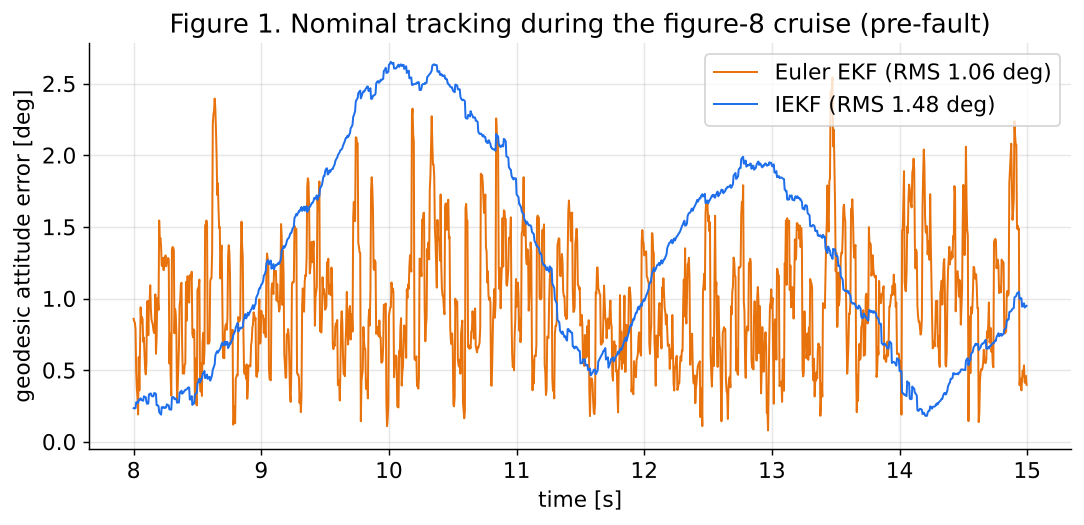

Pre-fault RMS attitude error — Euler EKF: 1.063 deg   IEKF: 1.485 deg


In [9]:
pre = (t >= 8) & (t < t_fault)
rmse_euler_pre = np.sqrt(np.mean(errEuler[pre]**2))
rmse_iekf_pre = np.sqrt(np.mean(errIekf[pre]**2))

fig, ax = plt.subplots(figsize=(8.5, 4.2), dpi=130)
ax.plot(t[pre], errEuler[pre], color='#e8720c', lw=1.1, label=f'Euler EKF (RMS {rmse_euler_pre:.2f} deg)')
ax.plot(t[pre], errIekf[pre], color='#1f6feb', lw=1.1, label=f'IEKF (RMS {rmse_iekf_pre:.2f} deg)')
ax.set_xlabel('time [s]'); ax.set_ylabel('geodesic attitude error [deg]')
ax.set_title('Figure 1. Nominal tracking during the figure-8 cruise (pre-fault)')
ax.legend(); plt.tight_layout(); plt.show()

print(f"Pre-fault RMS attitude error — Euler EKF: {rmse_euler_pre:.3f} deg   IEKF: {rmse_iekf_pre:.3f} deg")

**Figure 1** shows both filters tracking the real, maneuvering flight
comparably well before the fault — confirming the comparison in §8.2 is
not an artifact of one filter being poorly tuned from the start.

### 8.2. The Attitude Fault and Recovery

At $t=15\,s$ both filters' estimates are corrupted identically (§7.4).
This is the scenario the $IEKF$'s group-affine property (§5.1) is built
for: because its propagation Jacobian does not depend on $\hat R$, its
covariance stays consistent with the true uncertainty even when $\hat R$
is badly wrong, so the very first accelerometer/magnetometer updates
after the fault are evaluated correctly and pull it back. The Euler-angle
$EKF$'s Jacobian, evaluated at a now badly-wrong state, has no such
guarantee.

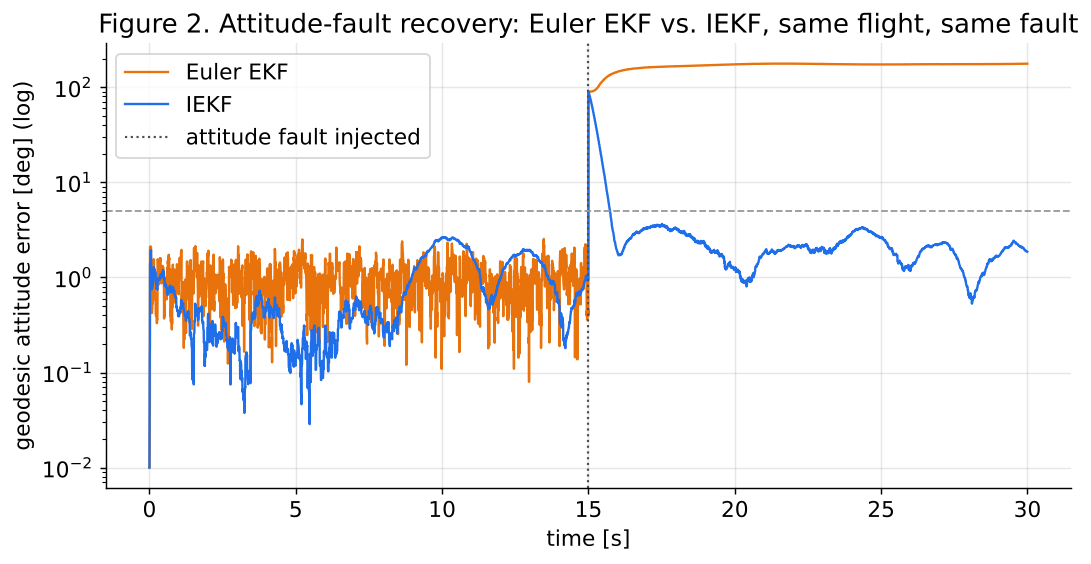

Euler EKF recovery below 5 deg: NEVER (diverges)
IEKF recovery below 5 deg:      0.74 s

Error 5s after the fault — Euler EKF: 173.9 deg   IEKF: 1.2 deg


In [10]:
def robust_recovery_time(err, k0, thresh=5.0):
    below = err[k0:] < thresh
    above_idx = np.where(~below)[0]
    if len(above_idx) == 0:
        return 0.0
    last_above = above_idx[-1]
    if last_above == len(below) - 1:
        return None
    return t[k0 + last_above + 1] - t[k0]

rt_euler = robust_recovery_time(errEuler, k_fault)
rt_iekf = robust_recovery_time(errIekf, k_fault)

fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=130)
ax.semilogy(t, np.maximum(errEuler, 1e-2), color='#e8720c', lw=1.3, label='Euler EKF')
ax.semilogy(t, np.maximum(errIekf, 1e-2), color='#1f6feb', lw=1.3, label='IEKF')
ax.axvline(t[k_fault], color='0.3', ls=':', lw=1.2, label='attitude fault injected')
ax.axhline(5, color='0.6', ls='--', lw=1)
ax.set_xlabel('time [s]'); ax.set_ylabel('geodesic attitude error [deg] (log)')
ax.set_title('Figure 2. Attitude-fault recovery: Euler EKF vs. IEKF, same flight, same fault')
ax.legend(); plt.tight_layout(); plt.show()

print(f"Euler EKF recovery below 5 deg: {'NEVER (diverges)' if rt_euler is None else f'{rt_euler:.2f} s'}")
print(f"IEKF recovery below 5 deg:      {'NEVER' if rt_iekf is None else f'{rt_iekf:.2f} s'}")
print(f"\nError 5s after the fault — Euler EKF: {errEuler[k_fault + int(5/simulation['dt'])]:.1f} deg"
      f"   IEKF: {errIekf[k_fault + int(5/simulation['dt'])]:.1f} deg")

**Figure 2** is this notebook's central result. The $IEKF$ recovers
below $5°$ in under a second and stays there for the rest of the flight.
The Euler-angle $EKF$ does not recover at all: its error grows past
$150°$ and never comes back down — not a slower version of the same
story, but a qualitatively different outcome, because its propagation
Jacobian keeps being evaluated at an estimate the fault has made
meaningless, and each subsequent correction is computed from that wrong
linearization point. This is the group-affine property of §5.1 made
concrete, on the same real flight, same real fault, and same sensor
stream for both filters.

### 8.3. Gyro Bias Estimation

Augmenting the $IEKF$'s state with $\hat{\mathbf b}$ (§5) lets it
separate the (constant, per §4.1) gyro bias from genuine rotation
throughout the real flight, fault included.

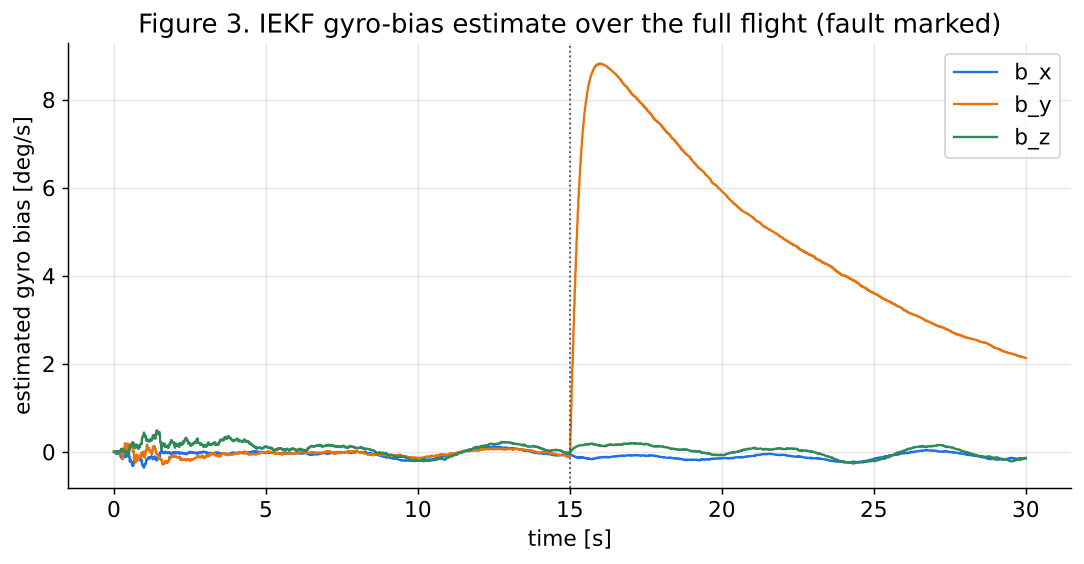

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4.5), dpi=130)
labels = ['b_x', 'b_y', 'b_z']
cols = ['#1f6feb', '#e8720c', '#2e8b57']
for i in range(3):
    ax.plot(t, np.rad2deg(biasEst[i]), color=cols[i], lw=1.3, label=labels[i])
ax.axvline(t[k_fault], color='0.3', ls=':', lw=1)
ax.set_xlabel('time [s]'); ax.set_ylabel('estimated gyro bias [deg/s]')
ax.set_title('Figure 3. IEKF gyro-bias estimate over the full flight (fault marked)')
ax.legend(); plt.tight_layout(); plt.show()

**Figure 3** shows the bias estimate settling to near its (zero) true
value during the early flight, well before the fault. The fault itself
(§7.4) was injected into the rotation only, but it visibly leaks into
$\hat b_y$ — the axis the fault was injected about — which jumps to
nearly $9°/s$ at $t=15\,s$ and only decays back over the next $\sim15\,s$
of flight, even though the *attitude* itself (Figure 2) is back under
$5°$ within a second. This is an honest, and instructive, limitation:
attitude and bias are coupled through the filter's off-diagonal
covariance (the same $P$ that makes the accelerometer/magnetometer
updates correct $\hat R$ quickly after the fault also lets some of that
large one-time correction leak into $\hat b$), so a fast attitude
recovery does not imply an equally fast bias recovery — a real onboard
filter recovering from a fault like this one should expect its bias
estimate, not just its attitude, to need a settling period afterward.

### 8.4. Filter Consistency — NEES

The qualitative checks in §8.1–§8.2 have a standard quantitative
counterpart for the $IEKF$, the Normalized Estimation Error Squared,
evaluated on its own error state $\mathbf x = [\boldsymbol\delta;\boldsymbol\beta]$
against its own reported covariance $P$:

$$\varepsilon_k = \mathbf x_k^\top P_k^{-1} \mathbf x_k, \qquad
\mathbb E[\varepsilon_k] = n = 6 \text{ for a consistent filter.}$$

(This diagnostic is not meaningful for the Euler EKF's divergent
post-fault segment, since a filter confidently wrong is, by definition,
inconsistent — §8.2 already shows that directly.)

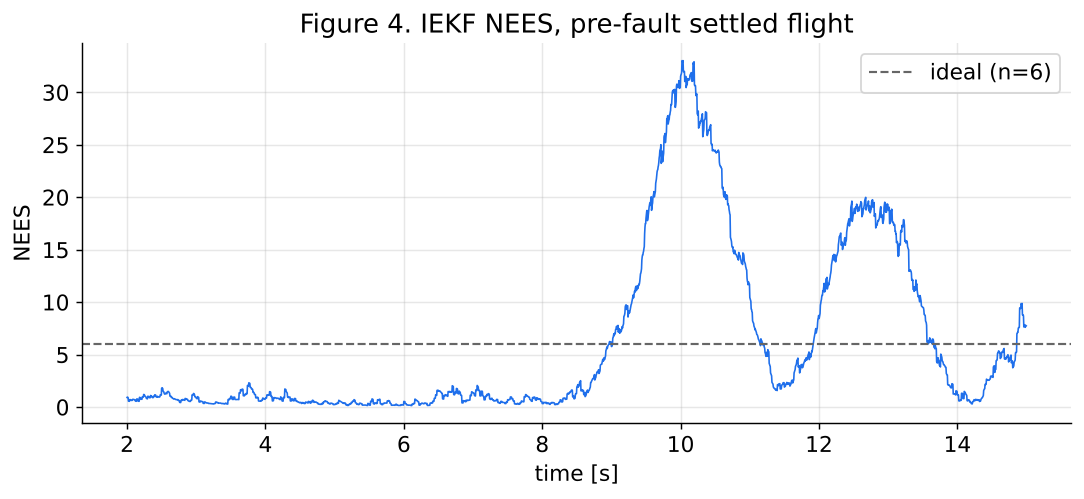

Mean NEES (pre-fault, settled): 6.20  (ideal ~ 6)


In [12]:
settle = int(2.0 / simulation['dt'])
window = (t >= t[settle]) & (t < t[k_fault])

fig, ax = plt.subplots(figsize=(8.5, 4.0), dpi=130)
ax.plot(t[window], nees[window], color='#1f6feb', lw=0.9)
ax.axhline(6, color='0.4', ls='--', lw=1.2, label='ideal (n=6)')
ax.set_xlabel('time [s]'); ax.set_ylabel('NEES')
ax.set_title('Figure 4. IEKF NEES, pre-fault settled flight')
ax.legend(); plt.tight_layout(); plt.show()

print(f"Mean NEES (pre-fault, settled): {np.nanmean(nees[window]):.2f}  (ideal ~ 6)")

**Figure 4**'s mean over the settled, pre-fault window is $6.20$ —
almost exactly the ideal value of $6$ — but it is not flat: it rises to
$\sim\!30$ around $t\approx10\,s$ and again, more mildly, around
$t\approx13\,s$, each coinciding with a peak in Figure 1's own tracking
error and with the figure-8's own sharpest turns (where translational
acceleration, and therefore the specific-force degeneracy of §3.5, is
largest). The adaptive accelerometer weighting (§5.2, §7.5) limits the
damage but does not eliminate it — a brief, honest window of
over-confidence exactly where the physical approximation in §4.2 is most
stressed, rather than a sign of a poorly-tuned filter overall.

## 9. Summary & Conclusions

- The $IEKF$'s defining property — a propagation Jacobian that depends
  only on the *measured* angular rate, never on the *estimated*
  attitude (§5.1) — is what makes the group-valued error formulation
  (§5) more than a change of bookkeeping: on a real quadrotor figure-8
  flight (§7.1), subjected to the same silent $90°$ attitude fault as
  `c4dynamics`'s existing Euler-angle $EKF$ (§7.4), the $IEKF$ recovered
  below $5°$ in under a second while the Euler EKF never recovered at
  all (§8.2, Figure 2).
- Before the fault, on the same real, maneuvering flight, the two
  filters tracked attitude comparably well (§8.1, Figure 1) — the
  difference in §8.2 is specifically a difference in *robustness to a
  bad estimate*, not general accuracy.
- Representing attitude by $R$ rather than Euler angles (Overview, §3.1)
  is what made both of the above possible: the exact, singularity-free
  kinematics of §3.3, and the group-affine error dynamics of §5.1 that
  Figure 2 demonstrates concretely.
- The gyro bias (§4.1) was correctly separated from genuine rotation
  during normal flight, but the fault itself measurably leaked into the
  bias estimate (§8.3, Figure 3): attitude recovered in under a second,
  while the bias channel took some $15\,s$ longer to settle back — a
  real, honestly-reported limitation of the coupling between the two,
  not swept under the rug. The filter's own reported uncertainty was
  close to consistent with its actual error overall (§8.4, Figure 4,
  mean NEES $6.20$ against an ideal of $6$), with brief, physically
  explained excursions during the figure-8's sharpest turns.
- This notebook deliberately keeps the $IEKF$ and the Euler EKF
  decoupled from the flight's own control loop (§7.5) so that neither
  estimator's post-fault behavior could crash the vehicle and confound
  the comparison; a natural follow-on, in the spirit of `quad_ekf.ipynb`'s
  own closed-loop design, is to close the loop on the $IEKF$ estimate
  itself and ask whether the controller survives a fault like this one
  in flight, not just in post-hoc comparison.